<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# ROC AUC - Solution

---

### About
An introduction to ROC AUC.


### Learning Objectives
- Demonstrate the ROC curve and the AUC score.


### Notebook Guide

- Imports
- Load Data Set and Model
- AUC Score
- Displaying the ROC Curve
- Interpreting ROC AUC
- Now You (if time)
- Conclusion and Summary

# Understanding ROC Curve and AUC

### 🎯 What is ROC AUC?

Most classification models do not natively output hard labels like "Class 0" or "Class 1." Instead, they calculate raw probability scores—such as a $78\%$ chance that a specific observation belongs to the positive class. 

**ROC AUC** is the industry-standard evaluation metric used to measure how effectively a model uses those raw probabilities to rank, sort, and separate your actual data points into their correct groups. 

Instead of checking whether individual guesses are right or wrong at a single cutoff point, ROC AUC evaluates the model's fundamental ability to assign higher probabilities to true positive samples than to true negative samples.



---

### 1. Breaking Down the Components

To understand ROC AUC, we must look at its two distinct parts: the **ROC Curve** (the visualization) and the **AUC** (the metric score).

#### A. The ROC Curve (Receiver Operating Characteristic)

The ROC curve is a 2D graph that plots a model's classification performance across all possible decision thresholds (from $0.0$ to $1.0$)
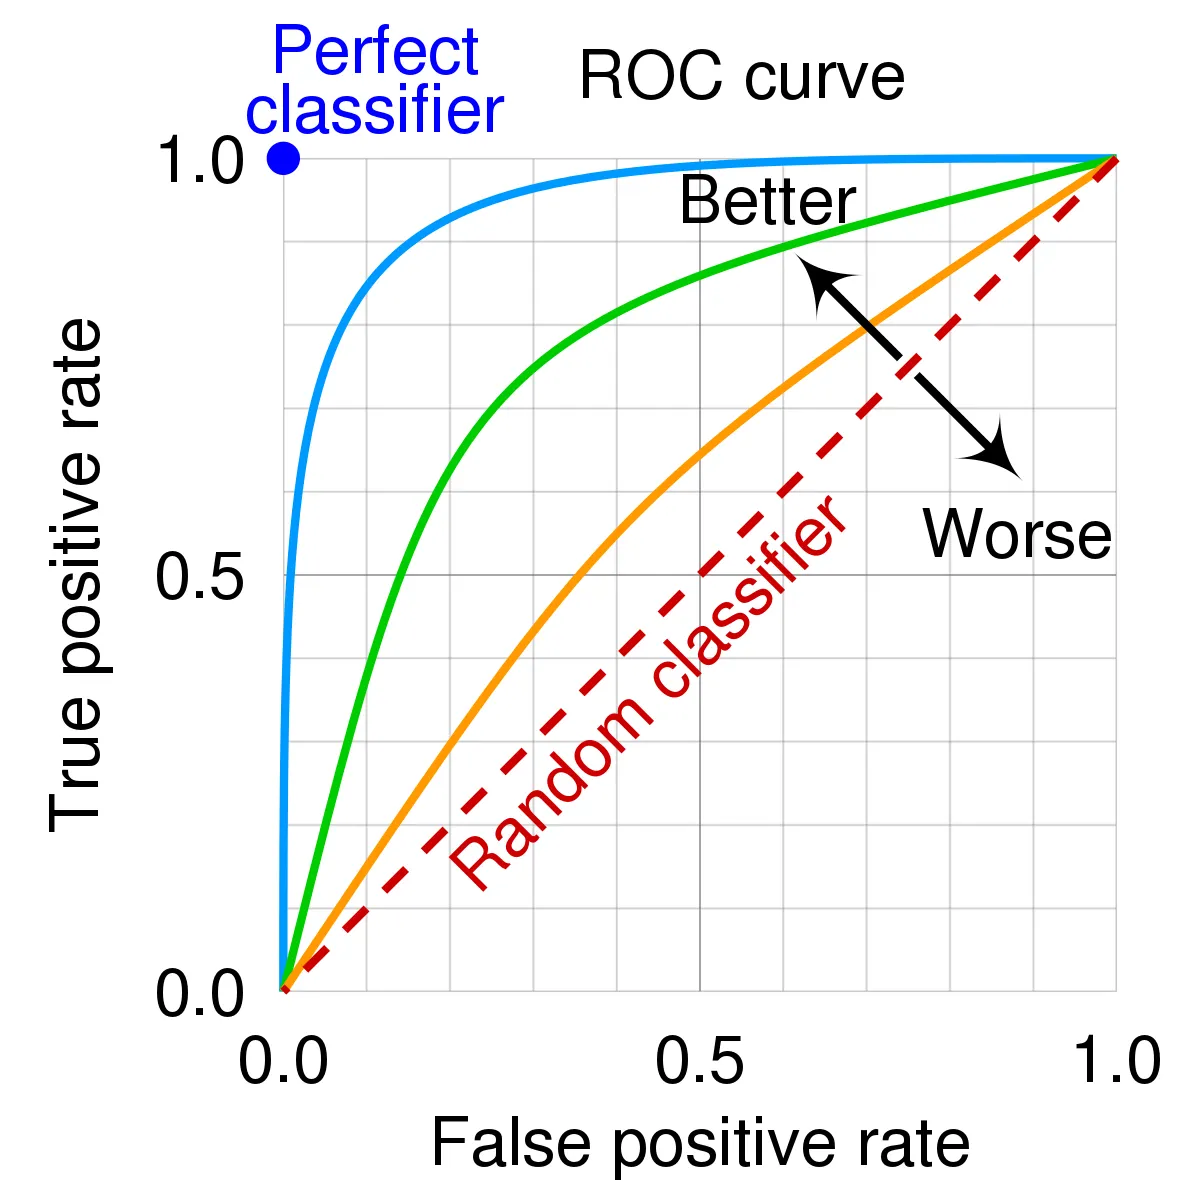

The graph pits two metrics against each other:
* **Y-Axis: True Positive Rate (TPR) / Recall / Sensitivity**
  $$\text{TPR} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}$$
  *Meaning:* Out of all actual positive cases, how many did the model catch? (Higher is better).
* **X-Axis: False Positive Rate (FPR) / 1 - Specificity**
  $$\text{FPR} = \frac{\text{False Positives}}{\text{False Positives} + \text{True Negatives}}$$
  *Meaning:* Out of all actual negative cases, how many did the model accidentally label as positive? (Lower is better).

As you lower your classification threshold, the model catches more true positives (TPR goes up), but it also triggers more false alarms (FPR goes up). The ROC curve traces this exact mathematical trade-off.

#### B. The AUC (Area Under the Curve)

The **AUC** distills the entire ROC graph into a single, comprehensive number between $0.0$ and $1.0$. It measures the total two-dimensional area locked underneath the plotted ROC curve.

---

### 🧠 The Statistical Interpretation of the AUC Score

While the area calculation sounds purely geometric, AUC has a beautiful probabilistic meaning in data science:

> **The AUC score represents the probability that the model will rank a randomly chosen positive sample higher than a randomly chosen negative sample.**

#### 📈 Grading Scale for AUC Scores:
* **$\text{AUC} = 1.0$ (Perfect Classifier):** The model separates classes flawlessly. Every single positive instance gets a higher probability score than every single negative instance. The ROC curve hugs the top-left corner.
* **$\text{AUC} = 0.5$ (Random Guessing):** The model has zero discriminatory power. It performs no better than flipping a fair coin. The ROC curve is a straight diagonal line.
* **$\text{AUC} < 0.5$ (Inverted Classifier):** The model is systematically predicting backwards. If you invert all of its predictions (flip 0 to 1 and 1 to 0), it will become a good model.

---




### 🔑 The Fundamental Distinction

The core difference between these two evaluation tools comes down to **operational scope**:

* **A Confusion Matrix is a local, single-threshold snapshot.** It provides a snapshot of a model's performance at one single, fixed decision threshold (e.g., 0.5)
* **ROC AUC is a global, threshold-agnostic metric.** It measures a model's ability to separate classes across every possible decision threshold simultaneously (from 0.0 to 1.0)


# Imports

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split

from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score

# Load Data Set and Model

Let's quickly prep a new data set and model to illustrate the ROC curve and AUC score.

In [63]:
# Load data
smoking = pd.read_csv('../data/Whickham.csv')

In [64]:
smoking.head()

,outcome,smoker,age
0,Alive,Yes,23
1,Alive,Yes,18
2,Dead,Yes,71
3,Alive,No,67
4,Alive,No,64


In [65]:
smoking.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1314 entries, 0 to 1313
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   outcome  1314 non-null   object
 1   smoker   1314 non-null   object
 2   age      1314 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 30.9+ KB


In [72]:
# Map categorical columns to 0s and 1s
smoking['outcome'] = smoking['outcome'].map({'Alive': 0, 'Dead': 1})
smoking['smoker'] = smoking['smoker'].map({'Yes': 1, 'No': 0})

In [67]:
# Separate X & y
X = smoking[['smoker', 'age']]
y = smoking['outcome']

In [ ]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=123)

In [68]:
# Train model
lr = LogisticRegression()
lr.fit(X_train, y_train)

0.8426395939086294
0.8267477203647416


In [ ]:
# Evaluate mode. Are we underfitting? overfitting?
print(lr.score(X_train, y_train))
print(lr.score(X_test, y_test))

In [70]:
# What's this again?
lr.predict_proba(X_test)[:5]

array([[0.86894442, 0.13105558],
       [0.62998715, 0.37001285],
       [0.94029576, 0.05970424],
       [0.41751764, 0.58248236],
       [0.47856539, 0.52143461]])

In [71]:
# Extract the probabilites for class 1
y_pred_prob = lr.predict_proba(X_test)[:, 1]

# AUC Score

In [73]:
# Can compute AUC immediately - nice!
# Note we use probabilities as the predicted target
roc_auc_score(y_test, y_pred_prob)

0.8919235002751787

### Understanding ROC AUC
#### ROC AUC is a way to measure how well your model can separate the positive cases from the negative cases.

Simple example:
- Imagine you have a model predicting if someone will get sick based on their temperature
- A perfect model (AUC = 1.0) would mean all sick people have high temperatures and all healthy people have low temperatures
- A useless model (AUC = 0.5) would mean temperature tells you nothing about who is sick
 
Why use ROC AUC instead of confusion matrix?
- Confusion matrix only shows results for one threshold (like 0.5)
- ROC AUC considers ALL possible thresholds from 0 to 1
- This gives you a more complete picture of model performance
 
The AUC score ranges from 0 to 1:
- 1.0 = Perfect separation (best possible model)
- 0.5 = Random guessing (useless model) 
- Below 0.5 = Worse than random (flip your predictions!)


# Displaying the ROC Curve

## Visualizing Thresholds on ROC Curve

The ROC curve shows the trade-off between True Positive Rate (TPR) and False Positive Rate (FPR) across **all possible thresholds** from 0 to 1. Each point on the ROC curve represents a different threshold value.

Let's see how to identify and visualize specific thresholds on the ROC curve:

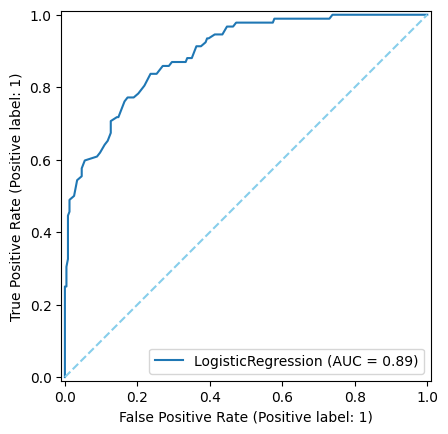

In [78]:
# Newer versions of scikit-learn:
RocCurveDisplay.from_estimator(estimator = lr, X = X_test, y = y_test) 

# Older versions of scikit-learn need this line instead of the one above:
# metrics.plot_roc_curve(lr, X_test, y_test, c='navy')


# Regardless of which line above you run, this line plots the ROC curve
sns.lineplot(x=[0, 1], y=[0, 1], color='skyblue', linestyle='--');

### Understanding Threshold Points on ROC Curve

**Key Points:**
- **Each point** on the ROC curve represents a different threshold value
- **Moving along the curve** from right to left means increasing the threshold (becoming more conservative)
- **Top-left corner** (0,1) = perfect classifier (100% TPR, 0% FPR)
- **Diagonal line** represents random chance (AUC = 0.5)

**What happens as threshold changes:**
- **Lower threshold**: More points classified as positive, curve moves toward top-right
- **Higher threshold**: More points classified as negative, curve moves toward bottom-left
- **Our model's curve**: Bends well above the diagonal, indicating good performance
- **AUC ≈ 0.90**: Shows strong ability to separate alive vs dead cases
---


# Interpreting ROC AUC
- If you have an ROC AUC of 0.5, your positive and negative populations perfectly overlap and your model is as bad as it can get.
- If you have an ROC AUC of 1, your positive and negative populations are perfectly separated and your model is as good as it can get.
- The closer your ROC AUC is to 1, the better. (1 is the maximum score.)

- If you have an ROC AUC of below 0.5, your positive and negative distributions have flipped sides. By flipping your predicted values (i.e. flipping predicted 1s and 0s), your ROC AUC will now be above 0.5.
    - Example: You have an ROC AUC of 0.2. If you change your predicted 1s to 0s and your predicted 0s to 1s, your ROC AUC will now be 0.8!
 
We generate one ROC curve per model. The ROC curve is generated by varying our threshold from 0 to 1. This doesn't actually change the threshold or our original predictions, but it helps us to visualize our tradeoff between _sensitivity_ and _specificity_ and understand how well-separated our populations are.

# Now You (if time)

Create a confusion matrix for this model, and then calculate these metrics:
- Accuracy
- Recall / Sensitivity / True Positive Rate (TPR)
- Precision
- F1 score

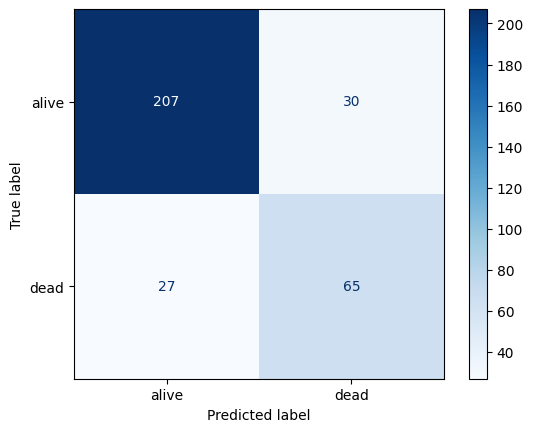

In [84]:
# Confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = ['alive', 'dead']
ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test,
                                 display_labels=class_names,
                                 cmap=plt.cm.Blues);


In [85]:
# Metrics

# need predicted target values
y_pred = lr.predict(X_test)

In [86]:
# Metrics

# Accuracy
print(f'Accuracy: {accuracy_score(y_test, y_pred)}')

# Recall / Sensitivity / True Positive Rate (TPR)
print(f'Recall / Sensitivity / True Positive Rate (TPR): {recall_score(y_test, y_pred)}')

# Precision
print(f'Precision: {precision_score(y_test, y_pred)}')

# F1 score
print(f'F1 score: {f1_score(y_test, y_pred)}')

Accuracy: 0.8267477203647416
Recall / Sensitivity / True Positive Rate (TPR): 0.7065217391304348
Precision: 0.6842105263157895
F1 score: 0.6951871657754011


# How to choose between metrics?

Choose the CV metric based on the business/medical objective, not based on a universal rule.

For example:

- **Cancer screening**: missing cancer is very costly → optimize Recall.
- **Spam detection**: falsely sending real emails to spam may be costly → optimize Precision.
- **Fraud detection**: both missing fraud and falsely blocking transactions matter → F1 may make sense.
- **You mainly care about overall ranking/separation and haven’t chosen a threshold yet**: use ROC AUC.
    - *Lead scoring / churn risk*: A company may rank customers by likelihood to churn and contact the top 5%, 10%, or 20% depending on campaign budget.

# Conclusion and Summary

Classification metrics are necessarily different from regression metrics since we can't mathematically compute residuals. So, there are a lot of different metrics to articulate the difference between $\mathbf{y}$ and $\mathbf{\hat y}$.

Metrics covered:
1. Accuracy and misclassification rate
1. Sensitivity and specificity
1. Precision and recall
1. $F_1$ and $F_\beta$
1. AUC score

Remember that, unlike for regression, not every metric is relevant all the time. **Framing the problem is a necessary first step!** Only then can you calculate a metric to answer your research goal.